Copyright (c) 2022 Robert Bosch GmbH

SPDX-License-Identifier: AGPL-3.0

# NuScenes data extractor

This script extracts the nuScenes data and stores it in a CSV file. The main execution block is located in the final cell. All preceding cells must be executed sequentially before running this final main block.

## Quick analysis of the scenes descriptors

In [1]:
from nuscenes.nuscenes import NuScenes
file_path_nuscenes="path"
nusc = NuScenes(version='v1.0-trainval', dataroot=file_path_nuscenes, verbose=True)

Loading NuScenes tables for version v1.0-trainval...
Loading nuScenes-panoptic...
32 category,
8 attribute,
4 visibility,
64386 instance,
12 sensor,
10200 calibrated_sensor,
2631083 ego_pose,
68 log,
850 scene,
34149 sample,
2631083 sample_data,
1166187 sample_annotation,
4 map,
34149 panoptic,
Done loading in 19.775 seconds.
Reverse indexing ...
Done reverse indexing in 10.5 seconds.


In [2]:


#nusc.list_scenes()



In [3]:
from collections import Counter
counter = Counter()

for i in range(len(nusc.scene)):
    my_scene = nusc.scene[i]
    l = my_scene["description"].split(",")
    c = Counter(l)
    counter.update(c)

print("\n\n##############################################\n")
print("Counter of all the terms occuring in each scene \n\n")
print(counter)



import numpy as np
import pandas as pd
df = pd.DataFrame.from_dict(counter, orient='index', columns=['Occurences'])
#df.plot.bar(figsize=(12,14))





##############################################

Counter of all the terms occuring in each scene 


Counter({' peds': 198, ' parked cars': 165, 'Rain': 148, ' parking lot': 134, 'Night': 98, ' bus': 92, ' turn right': 89, ' truck': 77, ' turn left': 75, ' cross intersection': 71, ' parked bicycle': 68, ' construction': 61, ' cones': 59, 'Parked cars': 56, ' wait at intersection': 55, 'Wait at intersection': 52, ' cars': 48, ' arrive at intersection': 47, ' peds on sidewalk': 46, ' parked bicycles': 39, ' jaywalker': 38, 'Parking lot': 37, ' bus stop': 36, ' many peds': 35, ' scooter': 33, ' bump': 32, ' construction vehicle': 31, ' peds crossing crosswalk': 31, ' ped': 31, ' ped crossing crosswalk': 28, ' bicycle rack': 27, ' motorcycle': 27, ' barriers': 24, ' bridge': 22, 'Turn left': 20, ' parked motorcycle': 18, ' parked trucks': 18, ' bicycle': 18, ' parked car': 18, ' parked scooter': 17, ' jaywalkers': 16, 'Turn right': 16, ' pedestrian': 15, ' trash cans': 14, ' nature': 14, '

## Visualize a pedestrian annotation

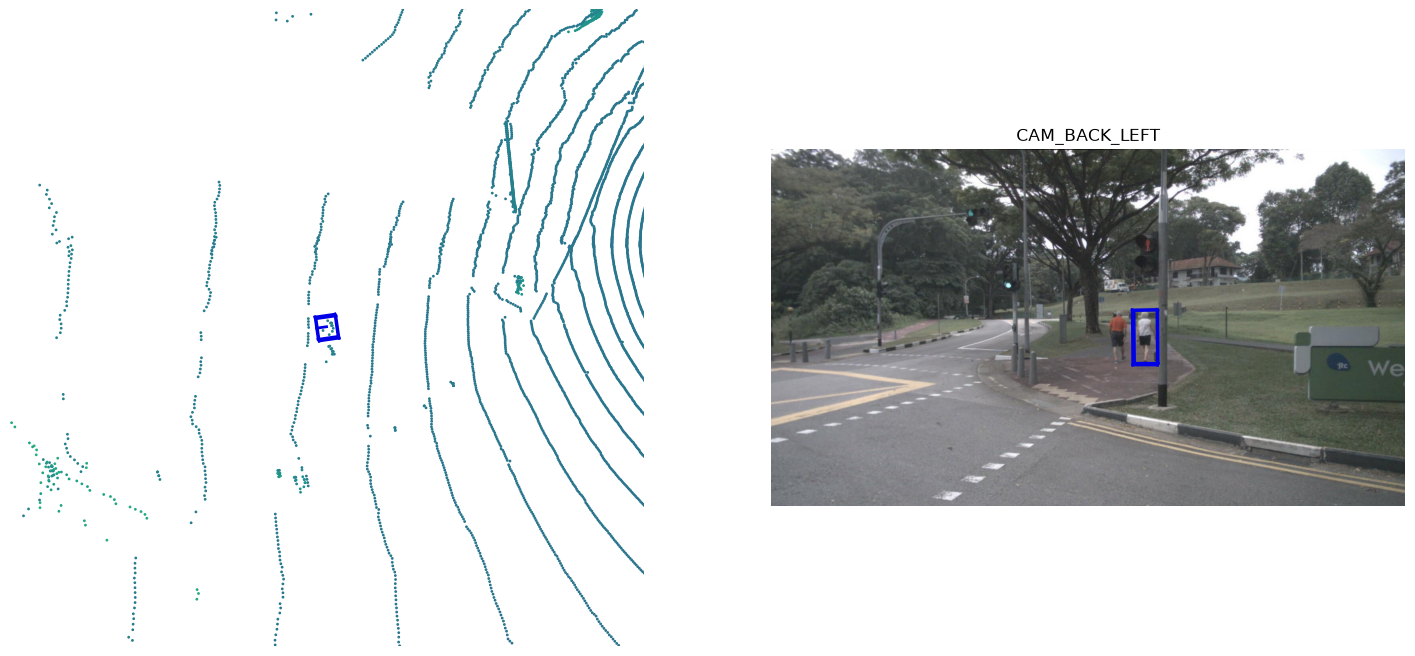

In [4]:
my_scene = nusc.scene[9]
first_sample_token = my_scene['first_sample_token']


my_sample = nusc.get('sample', first_sample_token)




my_annotation_token = my_sample['anns'][3]


nusc.render_annotation(my_annotation_token)





## Example of visualizing all annotation within an image

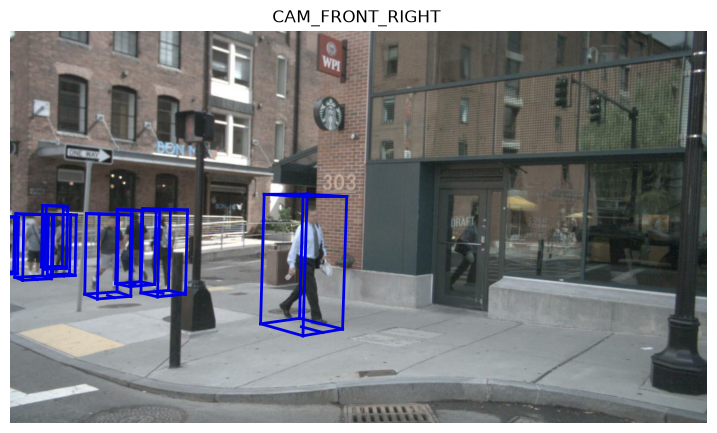

In [5]:
my_scene = nusc.scene[85]
first_sample_token = my_scene['first_sample_token']
sample_nr = 5

# Finds the sample_nr using recursion with sample["next"]"
def recursive_get_sample(token,sample_nr):
    if sample_nr==0:
        return token
    sample_nr = sample_nr -1
    sample = nusc.get('sample', token)
    token = sample['next']
    return recursive_get_sample(token, sample_nr)



sample_token = recursive_get_sample(first_sample_token, sample_nr)
my_sample = nusc.get('sample', sample_token)
#print(my_sample)

#sensor = 'CAM_FRONT_LEFT'
#sensor = 'CAM_FRONT_RIGHT'
sensor = 'CAM_FRONT_RIGHT'
cam_front_data = nusc.get('sample_data', my_sample['data'][sensor])


nusc.render_sample_data(cam_front_data['token'])
#nusc.render_annotation('b2222d3c49c447ba91247501e97d772b')

## Filtering of pedestrian annotations

In order to work with Monocular detection, the following cell removes
- Duplicate pedestrian annotations that are captured by adjacent cameras (e.g., CAM_FRONT, CAM_FRONT_RIGHT)
- Pedestrians that are truncated (in order to maintain occlusion level)

In [6]:
#Delete from mutal samples from left/right camera given the middle (front or back)

# First loop through box-visibility 1,  then stores all instances in which there are two in a camera
# if an instance list exists in two camerage imgs, then store it in list for later removing
def find_instances_in_within_two_camera_FOV(dict_cam_anns):
    camera_sensors = [['CAM_FRONT', "CAM_FRONT_RIGHT"],
                      ['CAM_FRONT_RIGHT', "CAM_BACK_RIGHT"],
                      ['CAM_BACK_RIGHT', "CAM_BACK"], 
                      ["CAM_BACK", "CAM_BACK_LEFT"], 
                      ["CAM_BACK_LEFT", "CAM_FRONT_LEFT"],
                      ["CAM_FRONT_LEFT", "CAM_FRONT"]]
    anntoken_duplicate_list = []
    
    for camera_comp in camera_sensors:
        for i in range(len(dict_cam_anns[camera_comp[0]])):
            for j in range(len(dict_cam_anns[camera_comp[1]])):
                anntoken1 = dict_cam_anns[camera_comp[0]][i].token
                anntoken2 = dict_cam_anns[camera_comp[1]][j].token
                
                if anntoken1==anntoken2:
                    #print("found double: {}".format(anntoken2))
                    anntoken_duplicate_list.append(anntoken1)
                    
    
    return anntoken_duplicate_list

def remove_duplicate_instances(dict_cam_anns, anntoken_list_duplicates):
    
    for sensor,boxes in list(dict_cam_anns.items()):
        box_list_updated = []
        for i in range(len(boxes)):
            if boxes[i].token not in anntoken_list_duplicates:
                box_list_updated.append(boxes[i])
            #else:
                #print("found duplicate: {}".format(boxes[i].token))
        dict_cam_anns[sensor] = box_list_updated
    return dict_cam_anns







#the box_visibility ranges from 0-2, and describes wether the bbox should be fully inside, 1 corner inside, or completley outside
#Check nuscenes-devkit documentiona for more infor on box_vis_level parameter

def get_filtered_FOV_dict_cam_anns(my_sample):
    box_visibility = 1
    boxes, cam = [], []
    cams = [key for key in my_sample['data'].keys() if 'CAM' in key]
    dict_cam_anns_box_visibility_1 = {key:value for (key,value) in zip(cam,boxes)}
    for cam in cams:
        _, boxes, _ = nusc.get_sample_data(my_sample['data'][cam], box_vis_level=box_visibility)#,selected_anntokens=['382d3f65c5da47649504196498f5490b'])
        dict_cam_anns_box_visibility_1[cam] = boxes
    ann_token_duplicate = find_instances_in_within_two_camera_FOV(dict_cam_anns_box_visibility_1)

    #Get all ann_token that are fully within an image, and remove duplicate ann_token from previous
    box_visibility = 0
    boxes, cam = [], []
    cams = [key for key in my_sample['data'].keys() if 'CAM' in key]
    dict_cam_anns_box_visibility_2 = {key:value for (key,value) in zip(cam,boxes)}
    for cam in cams:
        _, boxes, _ = nusc.get_sample_data(my_sample['data'][cam], box_vis_level=0)#,selected_anntokens=['382d3f65c5da47649504196498f5490b'])
        dict_cam_anns_box_visibility_2[cam] = boxes
    
    dict_cam_anns = remove_duplicate_instances(dict_cam_anns_box_visibility_2, ann_token_duplicate)
        
    return dict_cam_anns
    




# Transform 3D bounding box to 2D bounding box


- Create bbox from two min/max  3D points
- Create rectangle from the two corners that are farthers away from each other

samples/CAM_FRONT/n015-2018-07-18-11-18-34+0800__CAM_FRONT__1531884158414085.jpg


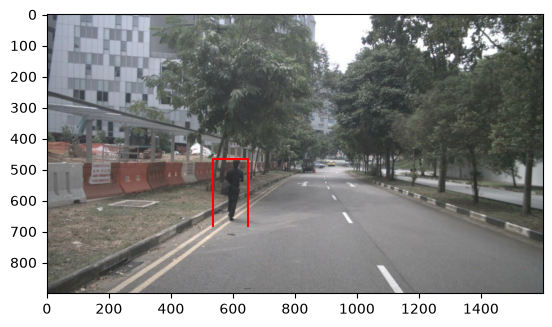

In [7]:
from nuscenes.utils.geometry_utils import view_points, box_in_image, BoxVisibility, transform_matrix
from matplotlib import pyplot as plt
from PIL import Image
from scipy.spatial import distance
from itertools import combinations

def get_2D_bbox(my_sample,box, sensor):
    #Projection of 3D into 2D code
    sd_record = nusc.get('sample_data', my_sample['data'][sensor])
    cs_record = nusc.get('calibrated_sensor', sd_record['calibrated_sensor_token'])
    cam_intrinsic = np.array(cs_record['camera_intrinsic'])
    #imsize = (sd_record['width'], sd_record['height'])

    corners_3d = box.corners()
    corners_img = view_points(corners_3d, cam_intrinsic, normalize=True)[:2, :]
    corners_img_reshape = np.asarray([[x,y] for x,y in zip(corners_img[0][:],corners_img[1][:])])
    comb_of_corners = list(combinations(corners_img_reshape, 2))
    
    #Loop through the corners to compute the distances from the origin
    distances = []
    for pair_of_corners in comb_of_corners:
        dst = distance.euclidean(pair_of_corners[0], pair_of_corners[1])
        distances.append(dst)
    
    
    bbox_corners = comb_of_corners[distances.index(max(distances))]
    if bbox_corners[0][0] < bbox_corners[1][0]:
        p1 = bbox_corners[0]
        p2 = bbox_corners[1]
    else:
        p1 = bbox_corners[1]
        p2 = bbox_corners[0]
    if p1[1] < p2[1]:
        temp = p1[1]
        p1[1] = p2[1]
        p2[1] = temp
    # Create rectangle
    bbox_2d = np.asarray([p1, [p1[0],p2[1]], p2 , [p2[0],p1[1]]])
   
    return bbox_2d

    




###################### Following code visualizes the projection on a sample image ##################################
my_scene = nusc.scene[5]
sample_nr = 3

camera_sensors = ['CAM_FRONT', "CAM_FRONT_RIGHT", "CAM_FRONT_LEFT", "CAM_BACK", "CAM_BACK_RIGHT", "CAM_BACK_LEFT"]
first_sample_token = my_scene['first_sample_token']
sample_token = recursive_get_sample(first_sample_token, sample_nr)
my_sample = nusc.get('sample', sample_token)
sensor = 'CAM_FRONT'
cam_front_data = nusc.get('sample_data', my_sample['data'][sensor])
#Projection of 3D into 2D code
sd_record = nusc.get('sample_data', my_sample['data'][sensor])
cs_record = nusc.get('calibrated_sensor', sd_record['calibrated_sensor_token'])
#show picture
print(sd_record['filename'])
img = Image.open(file_path_nuscenes + sd_record['filename'])
img.load()
data = np.asarray( img, dtype="int32" )
plt.imshow(data)



boxes, cam = [], []
cams = [key for key in my_sample['data'].keys() if 'CAM' in key]
dict_cam_anns = {key:value for (key,value) in zip(cam,boxes)}
for cam in cams:
    #print(cam)
    _, boxes, _ = nusc.get_sample_data(my_sample['data'][cam], box_vis_level=1)#,selected_anntokens=['382d3f65c5da47649504196498f5490b'])
    dict_cam_anns[cam] = boxes


bbox_2d = get_2D_bbox(my_sample,dict_cam_anns[sensor][0], sensor)
color = 'r'
#plt.scatter(bbox_2d, color=color)
plt.plot(bbox_2d[:,0], bbox_2d[:,1], color=color)
#plt.plot(bbox_corners[0], bbox_corners[1], color=color)
#plt.plot([p1[0],p2[0]],[p1[1],p2[1]])
#(array([1094.40121239,  476.32662999]), array([1413.82929466,  581.17080469]))
plt.show()

## Get blur detection

The cell below computes the blur level in the image. The method contains three steps

1. Convert image to grayscale
2. Compute the gradient of the image
3. compute the variance from step 2


The variance from step 3 determines blurriness, as blurri imaeges result in less steep gradients.


[[534.9348479  682.11843321]
 [534.9348479  466.7716584 ]
 [647.8511838  466.7716584 ]
 [647.8511838  682.11843321]]
682.1184332148292 682.1184332148292
534.9348479032058 534.9348479032058
[[  0.  -2.   8. ...  -1.  -1.   2.]
 [ -3.   2.   5. ...  -2.   2.   4.]
 [ -2.   3.   5. ...  -2.   1.   4.]
 ...
 [  9.   8.   7. ...   1.   1.  -2.]
 [ -7.  -3.   0. ...   0.  -3.  -1.]
 [-12. -17. -11. ...  -5.  -2.  -2.]]


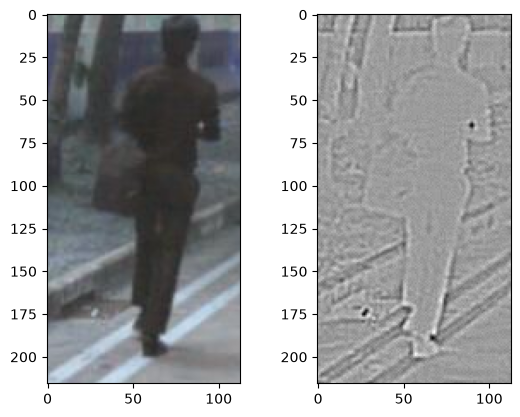

23.60053852345804


In [8]:
import argparse
import cv2
from matplotlib import pyplot as plt



def variance_of_laplacian(image):
    return cv2.Laplacian(image, cv2.CV_64F).var()



def get_blurr(img_path, bbox_2D):
    image = cv2.imread(img_path)
    image_cropp = image[int(bbox_2D[1][1]):int(bbox_2D[0][1]), int(bbox_2D[0][0]):int(bbox_2D[3][0])]
    image_cropp = cv2.GaussianBlur(image_cropp, (3, 3), 0)
    gray = cv2.cvtColor(image_cropp, cv2.COLOR_BGR2GRAY)
    blur_lvl = variance_of_laplacian(gray)
    return blur_lvl


image = cv2.imread(file_path_nuscenes + sd_record['filename'])
#print(image)
#plt.imshow(image)
#plt.show()

#n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542800861412460
#n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542800861912460.jpg
#print(dict_cam_anns)
bbox_2D = get_2D_bbox(my_sample, dict_cam_anns[sensor][0], sensor)
print(bbox_2D)
print(bbox_2D[0][1],bbox_2D[0][1])
print(bbox_2D[0][0],bbox_2D[1][0])
#image = image[400:700,200:400]
#image = image[700:400,400:100]
#image = image[500:700, 300:600]

image_cropp = image[int(bbox_2D[1][1]):int(bbox_2D[0][1]), int(bbox_2D[0][0]):int(bbox_2D[3][0])]
#image = image[514:601, 452:568]
plt.subplot(1, 2, 1)
plt.imshow(image_cropp)

image_cropp = cv2.GaussianBlur(image_cropp, (3, 3), 0)
gray = cv2.cvtColor(image_cropp, cv2.COLOR_BGR2GRAY)
blur_lvl = variance_of_laplacian(gray)
blur_threshold = 100

if blur_lvl < blur_threshold:
    text = "Blurry img"
    
cv2.putText(image, "{}: {:.2f}".format(text, blur_lvl), (10, 30),
		cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 3)




img = cv2.Laplacian(gray, cv2.CV_64F)

print(img)
plt.subplot(1, 2, 2)
plt.imshow(img, cmap='gray')


plt.show()
print(blur_lvl)

## Computing brightness


The cell below computes the brightness level in the images

In [9]:
import cv2
import numpy as np





def get_brightness_avg_pixel_lvl(img_path, bbox_2D):
    image = cv2.imread(img_path)
    image_cropp = image[int(bbox_2D[1][1]):int(bbox_2D[0][1]), int(bbox_2D[0][0]):int(bbox_2D[3][0])]
    hsv = cv2.cvtColor(image_cropp, cv2.COLOR_BGR2HSV)
    avg = np.mean(hsv[:,:, 2])
    per = (avg/255)*100
    return per



## Example of extracting visibility from an annotated pedestrian

In [10]:
anntoken = '0e81ee59e5bc4ab6ac069a75b333295b'
visibility_token = nusc.get('sample_annotation', dict_cam_anns[sensor][0].token)['visibility_token']
visibility_token = nusc.get('sample_annotation', anntoken)['visibility_token']

print("Visibility: {}".format(nusc.get('visibility', visibility_token)))


Visibility: {'description': 'visibility of whole object is between 60 and 80%', 'token': '3', 'level': 'v60-80'}


## Additional function declaration used in main execution block

In [11]:
 # compute the euclidean distance between translation in ego_pose and translation in sample_annotation 
    
    
def get_obj_distance(my_sample, sensor, box):
    cam_front_data = nusc.get('sample_data', my_sample['data'][sensor])
    ego_pose_token = cam_front_data["ego_pose_token"]
    ego_pose_data = nusc.get('ego_pose', ego_pose_token)
    #Extract object_translation
    #my_annotation_token = my_sample['anns'][18]
    # Extracting object distance
    # compute the euclidean distance between translation in ego_pose 32 and translation in sample_annotation 
    # Extract first ego_pose translation
    my_annotation_metadata =  nusc.get('sample_annotation', box.token)        
    dist_obj = math.dist(ego_pose_data["translation"], my_annotation_metadata["translation"] )
    
    return dist_obj



#######    note mabe the "description" will be lost because of the if branch ##########

################## Note   - Compute "many peds"/"dense traffic" manually by including how many people are in scene########

def get_car_occlusion(scene_description):

    if " dense traffic" in scene_description:
        value = 1
    elif " many cars" in scene_description:
        value = 1 
    elif " heavy traffic" in scene_description:
        value = 1
    elif " Heavy traffic" in scene_description:
        value = 1
    elif "Dense traffic" in scene_description:
        value = 1
    elif "Very dense traffic" in scene_description:
        value = 1
    elif " Many parked cars" in scene_description:
        value = 1
    elif " heavy traffic flow" in scene_description:
        value = 1
    elif " Heavy traffic flow" in scene_description:
        value = 1

    else:
        value = 0
    return value

#' many barrier'

def get_human_occlusion(scene_description):
    if " many peds" in scene_description:
        value = 1
    elif "Many peds" in scene_description:
        value = 1
    #elif "Several moving pedestrians" in scene_description:
    #    value = 1
    
    #elif " Several peds crossing road at crosswalk" in scene_description:
    #    value = 1
        
    #elif " seveal peds" in scene_description:
    #    value = 1
        
    elif ' several peds waiting for crossing' in scene_description:
        value = 1
        
    elif ' peds waiting' in scene_description:
        value = 1
    
    elif ' waiting peds' in scene_description:
        value = 1
        
    elif ' many peds in sidewalk' in scene_description:
        value = 1
        
    elif 'Many peds right' in scene_description:
        value = 1
        
    
    
    else:
        value = 0
    return value


def get_night(scene_description):
    if "Night" in scene_description:
        value = 1
    elif " Night" in scene_description:
        value = 1
    else:
        value = 0
    return value

def get_rain(scene_description):
    if "Rain" in scene_description:
        value = 1
    elif " rain" in scene_description:
        value = 1
    else:
        value = 0
    return value

def get_brightness_scene_desc(scene_description):
    if " difficult lighting" in scene_description:
        value = 1
    elif " lightning" in scene_description:
        value = 1
    else:
        value = 0
    return value




def quaternion_to_euler(q_w, q_x, q_y, q_z):
    # Roll (x-axis rotation)
    roll = math.atan2(2 * (q_w * q_x + q_y * q_z), 1 - 2 * (q_x**2 + q_y**2))
    
    # Pitch (y-axis rotation)
    pitch = math.asin(2 * (q_w * q_y - q_z * q_x))
    
    # Yaw (z-axis rotation)
    yaw = math.atan2(2 * (q_w * q_z + q_x * q_y), 1 - 2 * (q_y**2 + q_z**2))
    
    return roll, pitch, yaw

## Main execution block 

The cell below contains the main function of the script. It loops through every scene,sample, and annotations. The nuscenes metadata is therafter stored as a CSV file.

In [12]:
import math
#Code for extracting samples


data = []

human_category = ["human.pedestrian.adult", "human.pedestrian.child", "human.pedestrian.constructi", 
                  "human.pedestrian.personal_m", "human.pedestrian.police_off"]

camera_sensors = ['CAM_FRONT', "CAM_FRONT_RIGHT", "CAM_FRONT_LEFT", "CAM_BACK", "CAM_BACK_RIGHT", "CAM_BACK_LEFT"]


# Either pedestrian or vehicle detection




        
        
        
#############################      MAIN   LOOOP   #############################################
# loop through each Scene (i.e a "scene" is a scenario in classical automotive jargon)
for scene in range(len(nusc.scene)):
    my_scene = nusc.scene[scene]
    token = my_scene['first_sample_token']
    print("Scene number {}".format(scene))
    
    
    #Loop through each sample (i.e a "sample" is image taken within a scene)
    for sample_number in range(my_scene["nbr_samples"]):
        my_sample = nusc.get('sample', token)           
        dict_cam_anns = get_filtered_FOV_dict_cam_anns(my_sample)
        camera_sensors = dict_cam_anns.keys()
          
        
        #Loop through each camera and its annotatios(3D bboxes)
        for sensor,boxes in list(dict_cam_anns.items()):
            #Loop through boxes (annotations) in an image
            for box in boxes:
                

                ann_token = nusc.get('sample_annotation', box.token)
                #print(ann_token['category_name'][:7])
                if ann_token['category_name'][:5] != 'human':
                    continue
                #if ann_token['category_name'][:7] != 'vehicle':
                #    continue
                
                
                data_row_dic = {}
                #Extract visibility
                data_row_dic["ann_token"] = box.token
                data_row_dic["visibility"] = nusc.get('visibility', ann_token['visibility_token'])["token"]
                data_row_dic['category'] = ann_token['category_name']
                
                #Extract img-path
                cam_data = nusc.get('sample_data', my_sample['data'][sensor])
                data_row_dic["img_path"] = file_path_nuscenes + cam_data['filename'] 
                data_row_dic["camera"] = sensor
                
                #Extract object distance
                data_row_dic["obj_distance"] = get_obj_distance(my_sample, sensor, box)
                
                
                
                
                
                #Extract bounding box, xmin,ymin, xmax,ymax (top left is origo of 0,0, picture)
                bbox = get_2D_bbox(my_sample, box, sensor)
                data_row_dic["2D_bbox_x1"] = bbox[0][0]
                data_row_dic["2D_bbox_y1"] = bbox[2][1]
                data_row_dic["2D_bbox_x2"] = bbox[2][0]
                data_row_dic["2D_bbox_y2"] = bbox[0][1]
                
                
                #Extract 3D_bbox_GT
                data_row_dic["3D_bbox_x_center"] = box.center[0]
                data_row_dic["3D_bbox_y_center"] = box.center[1]
                data_row_dic["3D_bbox_z_center"] = box.center[2]
                data_row_dic["3D_bbox_w"] = box.wlh[0]
                data_row_dic["3D_bbox_l"] = box.wlh[1]
                data_row_dic["3D_bbox_h"] = box.wlh[2]
                
                roll, pitch, yaw = quaternion_to_euler(box.orientation[0], box.orientation[1], 
                                                       box.orientation[2], box.orientation[3])
                data_row_dic["3D_bbox_roll"] = roll 
                data_row_dic["3D_bbox_pitch"] = pitch
                data_row_dic["3D_bbox_yaw"] = yaw
                
                #Extract box velocity
                data_row_dic["velocity_x"] = box.velocity[0]
                data_row_dic["velocity_y"] = box.velocity[1]
                data_row_dic["velocity_z"] = box.velocity[2]

                
                
                #Extract blurr (store laplacian.var())
                data_row_dic["blurr_laplician_variance"] = get_blurr(data_row_dic["img_path"], bbox)
                #data_row_dic["blurr"] = True
                
                #Extract brightness
                data_row_dic["average_brightness_pixel_lvl"] = get_brightness_avg_pixel_lvl(data_row_dic["img_path"], bbox)
                
                
                    
                #Extract from scene_description
                scene_description = my_scene["description"].split(",")
                data_row_dic["is_night"] = get_night(scene_description)
                data_row_dic["is_rain"] = get_rain(scene_description)
                data_row_dic["high_speed"] = 1 if ' high speed' in scene_description else 0
                data_row_dic["difficult_lightning_brightness"] = get_brightness_scene_desc(scene_description)
                data_row_dic["car_occlusion"] = get_car_occlusion(scene_description)
                data_row_dic["human_occlusion"] = get_human_occlusion(scene_description)
                data_row_dic["scene_desc"] = scene_description
                
                data.append(data_row_dic)
        token = my_sample["next"]
    

    
    
    
    

    
    
    
    

############################ Store the data into CSV ##################################
    
    
import csv
fieldnames_3D = ['ann_token', 'camera', "img_path", "visibility", "difficult_lightning_brightness", "obj_distance",
              "is_night",'category', "blurr_laplician_variance","car_occlusion", "human_occlusion", "scene_desc", 
              "high_speed", "average_brightness_pixel_lvl", "is_rain",
                 "2D_bbox_x1", "2D_bbox_y1", "2D_bbox_x2", "2D_bbox_y2",
              "3D_bbox_x_center", "3D_bbox_y_center", "3D_bbox_z_center", "3D_bbox_w", "3D_bbox_l", "3D_bbox_h",
                 "3D_bbox_roll", "3D_bbox_pitch", "3D_bbox_yaw",
                 "velocity_x", "velocity_y", "velocity_z"]
with open('Pedestrians_annotations_filtered_FOV_with_rain_3D_bbox_eulerian_angels.csv', 'w', newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames_3D)
    writer.writeheader()
    for row_dic in data:
        writer.writerow(row_dic)

Scene number 0
Scene number 1
Scene number 2
Scene number 3
Scene number 4
Scene number 5
Scene number 6
Scene number 7
Scene number 8
Scene number 9
Scene number 10
Scene number 11
Scene number 12
Scene number 13
Scene number 14
Scene number 15
Scene number 16
Scene number 17
Scene number 18
Scene number 19
Scene number 20
Scene number 21
Scene number 22
Scene number 23
Scene number 24
Scene number 25
Scene number 26
Scene number 27
Scene number 28


KeyboardInterrupt: 